# 03 · Analysis: customers, cities and where to grow

**Business questions**
1. How is Hearthline performing, and which stores under- or over-perform **relative to the real size of their local market**?
2. Who are our customers? (RFM segmentation)
3. Do new customers come back? (cohort retention)
4. Which products are bought together? (market basket analysis)
5. Where should we grow next: a second store, or online abroad (US, Taiwan)?

The data is cleaned with the **same rules as SQL script 03**, so this notebook runs without a database.

In [1]:
import os
import pandas as pd, numpy as np, matplotlib.pyplot as plt

os.makedirs("images", exist_ok=True)
BLUE, VIOLET, ORANGE, AQUA, YELLOW = "#2a78d6", "#6250d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SOURCE = "Source: simulated Hearthline transactions, calibrated to real ONS and CSO statistics."
REAL = "Sources: ONS (J4MC); US Census Bureau via FRED (ECOMPCTSA); Taiwan Ministry of Economic Affairs."
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10,
})

def headline(fig, title, subtitle, top=0.95, source=SOURCE):
    fig.subplots_adjust(top=top)
    fig.text(0.01, 1.04, title.replace("$", r"\$"), fontsize=14, fontweight="bold", color=INK)
    fig.text(0.01, 1.00, subtitle.replace("$", r"\$"), fontsize=10, color=INK_2)
    fig.text(0.01, -0.03, source, fontsize=8, color=INK_2)

## 1. Load and clean (mirrors SQL script 03)

In [2]:
orders    = pd.read_csv("data/simulated/orders.csv", parse_dates=["order_datetime"], dtype={"promo_code": str})
lines     = pd.read_csv("data/simulated/order_lines.csv")
products  = pd.read_csv("data/simulated/products.csv")
customers = pd.read_csv("data/simulated/customers.csv")
stores    = pd.read_csv("data/simulated/stores.csv")
returns   = pd.read_csv("data/simulated/returns.csv")
city      = pd.read_csv("data/clean/city_profile.csv")

# 1. duplicates, 2. zero-price test lines, 3. guest checkouts, 4. messy city names
lines = lines.drop_duplicates("order_line_id")
lines = lines[lines["unit_price"] > 0]
orders["customer_id"] = orders["customer_id"].fillna("GUEST")
customers["home_city"] = customers["home_city"].str.strip().str.lower().replace("mcr", "manchester").str.title()

sales = (lines.merge(orders, on="order_id").merge(products[["product_id", "category", "subcategory", "unit_cost"]], on="product_id"))
sales["net_sales"] = sales["unit_price"] * sales["quantity"] * (1 - sales["discount_pct"])
sales["cogs"] = sales["unit_cost"] * sales["quantity"]
returns = returns.merge(sales[["order_line_id", "unit_price", "discount_pct", "channel", "store_id"]], on="order_line_id")
returns["refund"] = returns["quantity_returned"] * returns["unit_price"] * (1 - returns["discount_pct"])
SNAPSHOT = pd.Timestamp("2026-09-30")
print(f"{len(sales):,} clean sales lines")

825,425 clean sales lines


## 2. Headline KPIs

In [3]:
sales["year"] = sales["order_datetime"].dt.year
ytd = sales[sales["order_datetime"].dt.month <= 9]               # Jan–Sep, so 2026 is comparable
returns["year"] = pd.to_datetime(returns["return_date"]).dt.year
kpi = ytd.groupby("year").agg(revenue=("net_sales", "sum"), orders=("order_id", "nunique"),
                              customers=("customer_id", lambda s: s[s != "GUEST"].nunique()),
                              cogs=("cogs", "sum"))
kpi["avg_order_value"] = kpi["revenue"] / kpi["orders"]
kpi["gross_margin_pct"] = (1 - kpi["cogs"] / kpi["revenue"]) * 100
kpi["online_share_pct"] = ytd.groupby("year").apply(lambda d: d.loc[d["channel"] == "Online", "net_sales"].sum() / d["net_sales"].sum() * 100)
kpi["revenue_growth_pct"] = kpi["revenue"].pct_change() * 100
kpi.drop(columns="cogs").round(1)

,revenue,orders,customers,avg_order_value,gross_margin_pct,online_share_pct,revenue_growth_pct
year,,,,,,,
2024,4374307.3,87052,13500,50.2,51.5,30.0,NaN
2025,4530683.4,90501,18550,50.1,51.5,30.1,3.6
2026,4706508.5,93238,19979,50.5,51.4,32.3,3.9


## 3. Stores vs. the real size of their market

**Market capture index** = the store's share of company store revenue ÷ the city's share of spending power (real ONS/CSO data).
Above 1: the store wins more than its "fair share". Below 1: the city has room for more trade.

In [4]:
last12 = sales[(sales["order_datetime"] > SNAPSHOT - pd.DateOffset(years=1)) & (sales["channel"] == "Store")]
st = last12.merge(stores[["store_id", "city"]], on="store_id").groupby("city")["net_sales"].sum().rename("revenue")
cap = city.set_index("city")[["population", "spending_power_gbp_m", "retail_pull_index"]].join(st)
cap["revenue_share"] = cap["revenue"] / cap["revenue"].sum()
cap["spending_share"] = cap["spending_power_gbp_m"] / cap["spending_power_gbp_m"].sum()
cap["market_capture_index"] = cap["revenue_share"] / cap["spending_share"]
cap = cap.sort_values("market_capture_index")
cap[["population", "revenue", "revenue_share", "spending_share", "market_capture_index", "retail_pull_index"]].round(3)

,population,revenue,revenue_share,spending_share,market_capture_index,retail_pull_index
city,,,,,,
London,9122909,891003.553,0.209,0.424,0.493,0.936
Birmingham,3027190,364507.470,0.085,0.076,1.126,1.114
Manchester,3017590,406376.302,0.095,0.083,1.141,1.261
Leeds,2424324,335993.414,0.079,0.065,1.206,1.106
Glasgow,1898140,300615.590,0.070,0.055,1.288,0.885
Dublin,1597700,325487.366,0.076,0.057,1.331,0.910
Edinburgh,1426250,277066.601,0.065,0.049,1.335,0.720
Cardiff,1564798,265052.469,0.062,0.043,1.449,0.910
Liverpool,1610919,274941.650,0.064,0.044,1.459,0.980


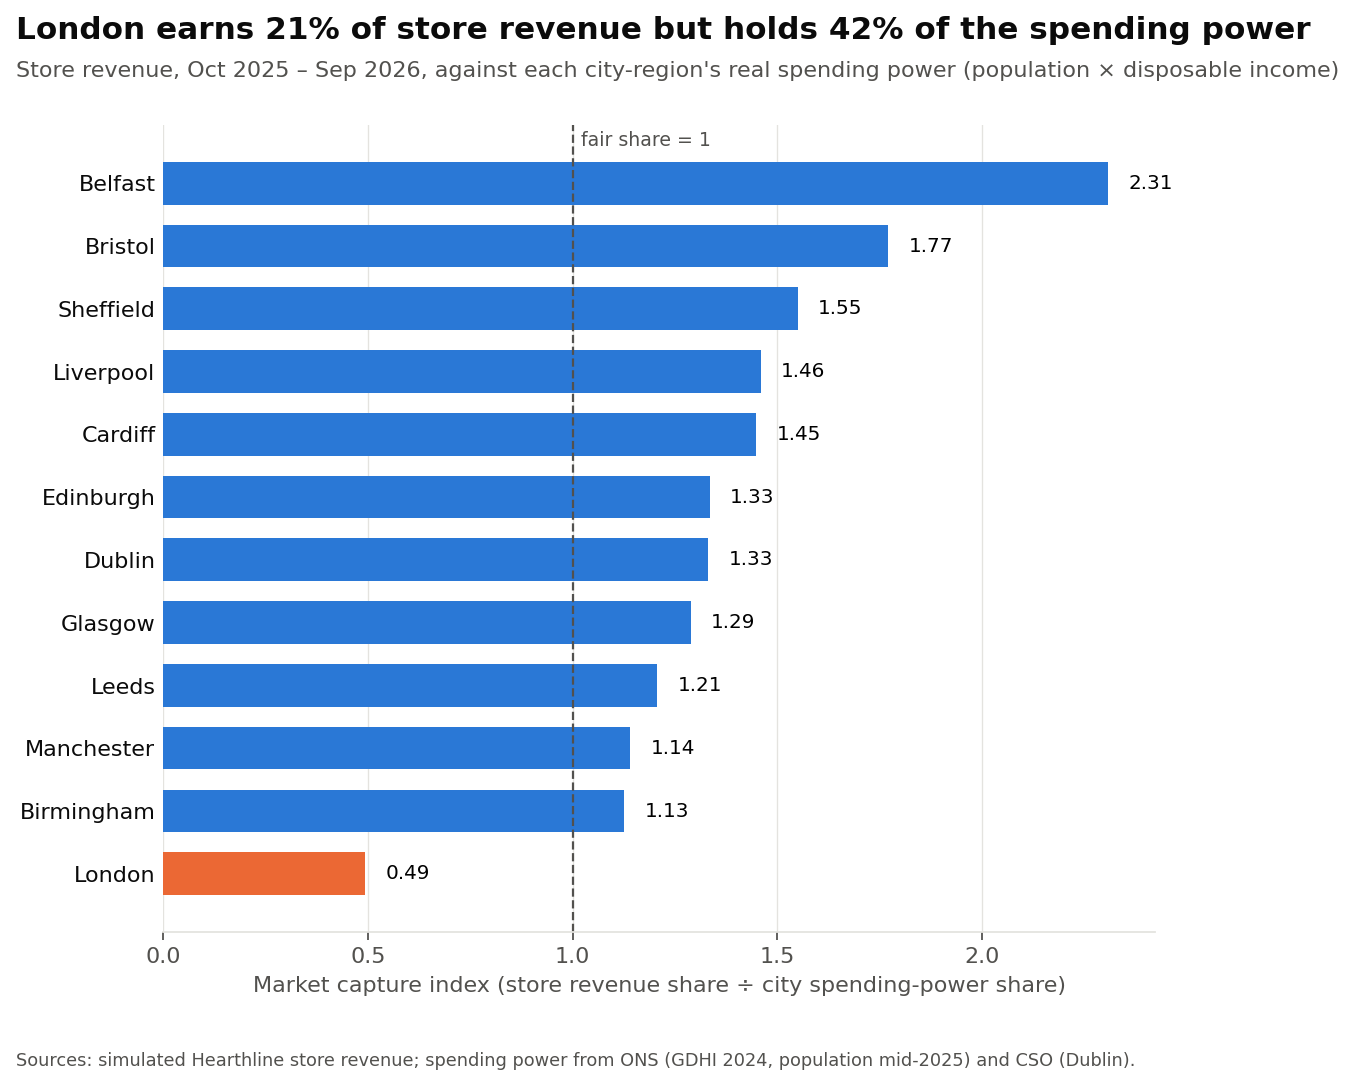

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = [ORANGE if c == "London" else BLUE for c in cap.index]
ax.barh(cap.index, cap["market_capture_index"], color=colors, height=0.68)
ax.axvline(1, color=INK_2, linestyle="--", linewidth=1)
ax.text(1.02, len(cap) - 0.4, "fair share = 1", color=INK_2, fontsize=8.5)
for i, v in enumerate(cap["market_capture_index"]):
    ax.text(v + 0.05, i, f"{v:.2f}", va="center", fontsize=9)
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
ax.set_xlabel("Market capture index (store revenue share ÷ city spending-power share)")
lon = cap.loc["London"]
headline(fig, f"London earns {lon['revenue_share']:.0%} of store revenue but holds {lon['spending_share']:.0%} of the spending power",
         "Store revenue, Oct 2025 – Sep 2026, against each city-region's real spending power (population × disposable income)",
         source="Sources: simulated Hearthline store revenue; spending power from ONS (GDHI 2024, population mid-2025) and CSO (Dublin).")
plt.savefig("images/1_market_capture.png"); plt.show()

### Sensitivity: how much does the London result depend on the store-capacity assumption?

In the simulation each store's share of in-store orders is proportional to its city-region's retail output raised to an exponent (0.45, an assumption). Below, the **expected** capture index is recalculated for exponents from 0.3 to 1.0, using only the official data. An exponent of 1 means store sales grow in proportion to the market; lower values mean one store captures less of a large market.

In [6]:
spend_share = city.set_index("city")["spending_power_gbp_m"] / city["spending_power_gbp_m"].sum()
rows = []
for e in [0.3, 0.45, 0.6, 0.8, 1.0]:
    w = city.set_index("city")["retail_gva_gbp_m"] ** e
    idx = (w / w.sum()) / spend_share
    rows.append({"exponent": e, "London index": idx["London"], "lowest other city": idx.drop("London").min(),
                 "cities below 1": int((idx < 1).sum())})
sensitivity = pd.DataFrame(rows).round(2)
sensitivity.to_csv("data/clean/capture_sensitivity.csv", index=False, lineterminator="\n")
sensitivity

,exponent,London index,lowest other city,cities below 1
0,0.30,0.34,1.15,1
1,0.45,0.43,1.21,1
2,0.60,0.55,1.12,1
3,0.80,0.73,0.91,2
4,1.00,0.94,0.72,8


## 4. Who are our customers? RFM segmentation

Each customer gets a 1–5 score for **R**ecency (days since last order), **F**requency (number of orders) and **M**onetary value (total spend) over the last 12 months, using quintiles. Scores are combined into named segments.

In [7]:
known = sales[(sales["customer_id"] != "GUEST") & (sales["order_datetime"] > SNAPSHOT - pd.DateOffset(years=1))]
rfm = known.groupby("customer_id").agg(last_order=("order_datetime", "max"), frequency=("order_id", "nunique"),
                                       monetary=("net_sales", "sum"))
rfm["recency_days"] = (SNAPSHOT - rfm["last_order"]).dt.days
rfm["R"] = pd.qcut(rfm["recency_days"], 5, labels=[5, 4, 3, 2, 1]).astype(int)           # recent = high score
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(r):
    if r.R >= 4 and r.F >= 4: return "Champions"
    if r.R >= 3 and r.F >= 3: return "Loyal"
    if r.R >= 4 and r.F <= 2: return "New / promising"
    if r.R <= 2 and r.F >= 3: return "At risk"
    if r.R <= 2 and r.F <= 2: return "Hibernating"
    return "Needs attention"

rfm["segment"] = rfm.apply(segment, axis=1)
seg = rfm.groupby("segment").agg(customers=("monetary", "size"), revenue=("monetary", "sum"),
                                 avg_orders=("frequency", "mean"), avg_spend=("monetary", "mean"))
seg["customer_share"] = seg["customers"] / seg["customers"].sum()
seg["revenue_share"] = seg["revenue"] / seg["revenue"].sum()
seg = seg.sort_values("revenue", ascending=False)
rfm.reset_index().to_csv("data/clean/rfm_segments.csv", index=False, lineterminator="\n")
seg.round(2)

,customers,revenue,avg_orders,avg_spend,customer_share,revenue_share
segment,,,,,,
Champions,5941,3208314.94,11.13,540.03,0.25,0.58
Loyal,4417,1021761.70,4.61,231.32,0.19,0.18
At risk,3625,711614.50,4.14,196.31,0.16,0.13
Hibernating,5664,347017.52,1.25,61.27,0.24,0.06
New / promising,1949,138911.09,1.35,71.27,0.08,0.03
Needs attention,1709,124065.59,1.32,72.60,0.07,0.02


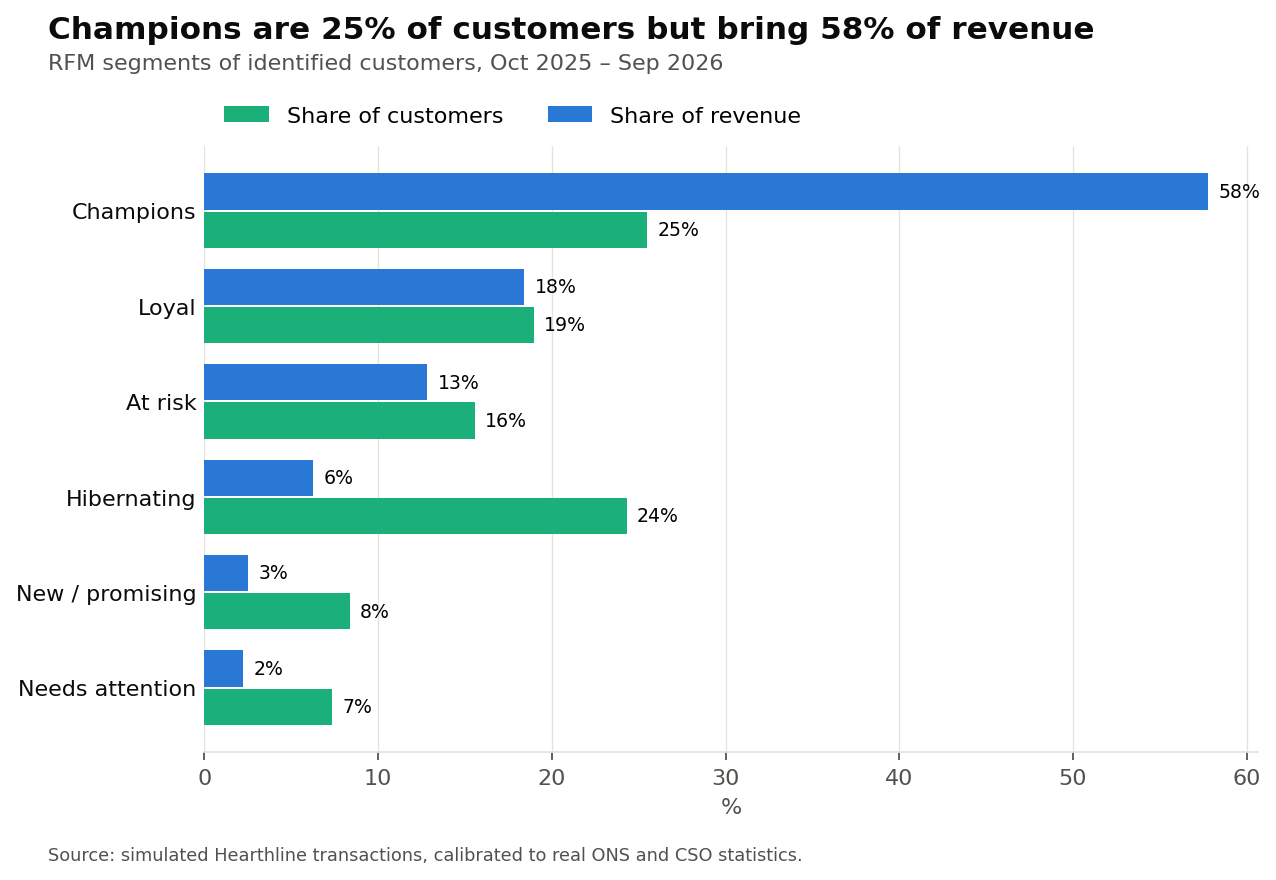

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
y = np.arange(len(seg))
ax.barh(y + 0.2, seg["customer_share"] * 100, height=0.38, color=AQUA, label="Share of customers")
ax.barh(y - 0.2, seg["revenue_share"] * 100, height=0.38, color=BLUE, label="Share of revenue")
for i, (c, r) in enumerate(zip(seg["customer_share"], seg["revenue_share"])):
    ax.text(c * 100 + 0.6, i + 0.2, f"{c:.0%}", va="center", fontsize=8.5)
    ax.text(r * 100 + 0.6, i - 0.2, f"{r:.0%}", va="center", fontsize=8.5)
ax.set_yticks(y, seg.index); ax.invert_yaxis()
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
ax.set_xlabel("%"); ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)
ch = seg.loc["Champions"]
headline(fig, f"Champions are {ch['customer_share']:.0%} of customers but bring {ch['revenue_share']:.0%} of revenue",
         "RFM segments of identified customers, Oct 2025 – Sep 2026", top=0.9)
plt.savefig("images/2_rfm_segments.png"); plt.show()

## 5. Do new customers come back? Quarterly cohort retention

In [9]:
cust_orders = sales[sales["customer_id"] != "GUEST"][["customer_id", "order_datetime"]].drop_duplicates()
first = cust_orders.groupby("customer_id")["order_datetime"].min().dt.to_period("Q").rename("cohort")
cust_orders = cust_orders.join(first, on="customer_id")
cust_orders["q"] = cust_orders["order_datetime"].dt.to_period("Q")
cust_orders["age"] = (cust_orders["q"] - cust_orders["cohort"]).apply(lambda x: x.n)
cohort = cust_orders.drop_duplicates(["customer_id", "age"]).groupby(["cohort", "age"])["customer_id"].nunique().unstack()
retention = cohort.div(cohort[0], axis=0) * 100
retention = retention[retention.index >= pd.Period("2024Q2")]      # 2024Q1 mixes in existing customers
retention.stack().rename("retention_pct").reset_index().rename(columns={"age": "quarters_since_first"}).astype({"cohort": str}).round(1).to_csv("data/clean/cohort_retention.csv", index=False, lineterminator="\n")
retention.round(0)

age,0,1,2,3,4,5,6,7,8,9,10
cohort,,,,,,,,,,,
2024Q2,100.0,58.0,49.0,36.0,30.0,25.0,22.0,18.0,16.0,15.0,NaN
2024Q3,100.0,58.0,42.0,36.0,30.0,27.0,22.0,19.0,17.0,NaN,NaN
2024Q4,100.0,51.0,42.0,34.0,30.0,24.0,21.0,19.0,NaN,NaN,NaN
2025Q1,100.0,52.0,42.0,37.0,28.0,27.0,22.0,NaN,NaN,NaN,NaN
2025Q2,100.0,51.0,44.0,34.0,29.0,24.0,NaN,NaN,NaN,NaN,NaN
2025Q3,100.0,54.0,40.0,36.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN
2025Q4,100.0,47.0,40.0,35.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026Q1,100.0,51.0,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026Q2,100.0,49.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


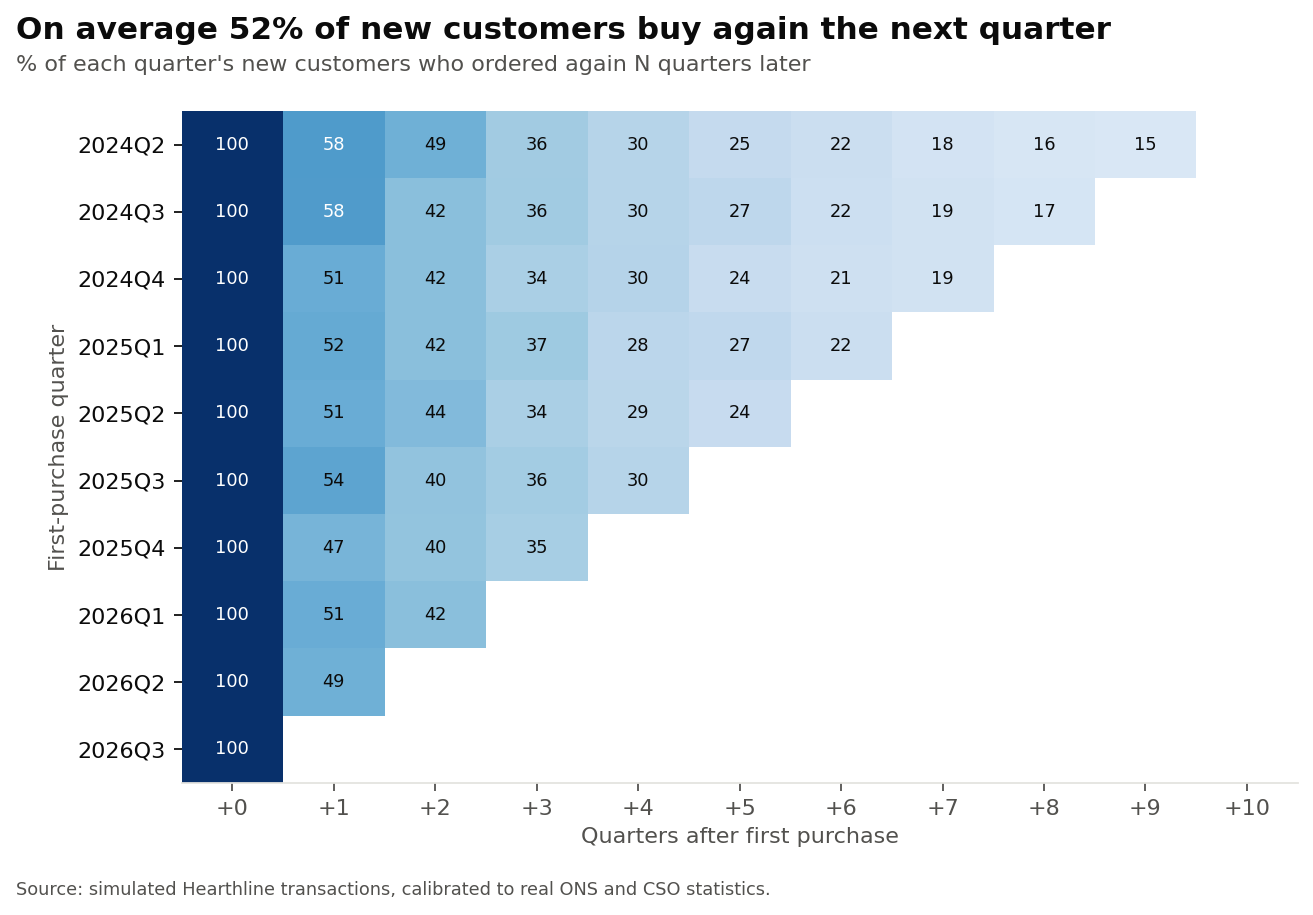

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(retention.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(retention.shape[1]), [f"+{a}" for a in retention.columns])
ax.set_yticks(range(len(retention)), [str(p) for p in retention.index])
for i in range(retention.shape[0]):
    for j in range(retention.shape[1]):
        v = retention.iat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 55 else INK)
ax.grid(False); ax.set_xlabel("Quarters after first purchase"); ax.set_ylabel("First-purchase quarter")
q1 = retention[1].mean()
headline(fig, f"On average {q1:.0f}% of new customers buy again the next quarter",
         "% of each quarter's new customers who ordered again N quarters later")
plt.savefig("images/3_cohort_retention.png"); plt.show()

## 6. What is bought together? Market basket analysis

For each pair of subcategories: **support** (share of orders with both), **confidence** (P(B | A)) and **lift** (how much more often than chance). Lift above 1 means a real association, which is useful for bundles and "you may also like".

In [11]:
basket = sales[["order_id", "subcategory"]].drop_duplicates()
n_orders = basket["order_id"].nunique()
item_n = basket.groupby("subcategory")["order_id"].nunique()
multi = basket[basket.groupby("order_id")["subcategory"].transform("size") > 1]
pairs = multi.merge(multi, on="order_id")
pairs = pairs[pairs["subcategory_x"] < pairs["subcategory_y"]]
pair_n = pairs.groupby(["subcategory_x", "subcategory_y"]).size().rename("orders_with_both").reset_index()
pair_n["support_pct"] = pair_n["orders_with_both"] / n_orders * 100
pair_n["lift"] = pair_n["orders_with_both"] * n_orders / (item_n.reindex(pair_n["subcategory_x"]).values * item_n.reindex(pair_n["subcategory_y"]).values)
pair_n["confidence_pct"] = pair_n["orders_with_both"] / item_n.reindex(pair_n["subcategory_x"]).values * 100
top_pairs = pair_n[pair_n["orders_with_both"] >= 200].sort_values("lift", ascending=False).head(8)
pair_n[pair_n["orders_with_both"] >= 200].sort_values("lift", ascending=False).round(3).to_csv("data/clean/basket_pairs.csv", index=False, lineterminator="\n")
top_pairs.round(2)

,subcategory_x,subcategory_y,orders_with_both,support_pct,lift,confidence_pct
519,Gift Set,Wrapping Kit,2523,0.74,21.51,36.83
304,Dinner Plate Set,Linen Napkins,5393,1.58,11.85,25.76
602,LED Bulb Pack,Table Lamp,7056,2.06,10.93,54.16
398,Faux Plant,Plant Pot,4984,1.46,8.75,60.46
176,Candle Holder,Scented Candle,12820,3.75,5.49,62.60
249,Coffee Beans,Stoneware Mug,8037,2.35,5.47,46.76
41,Bath Mat,Bath Towel,13631,3.99,4.73,49.17
338,Duvet Cover,Pillowcase Pair,1824,0.53,4.28,49.95


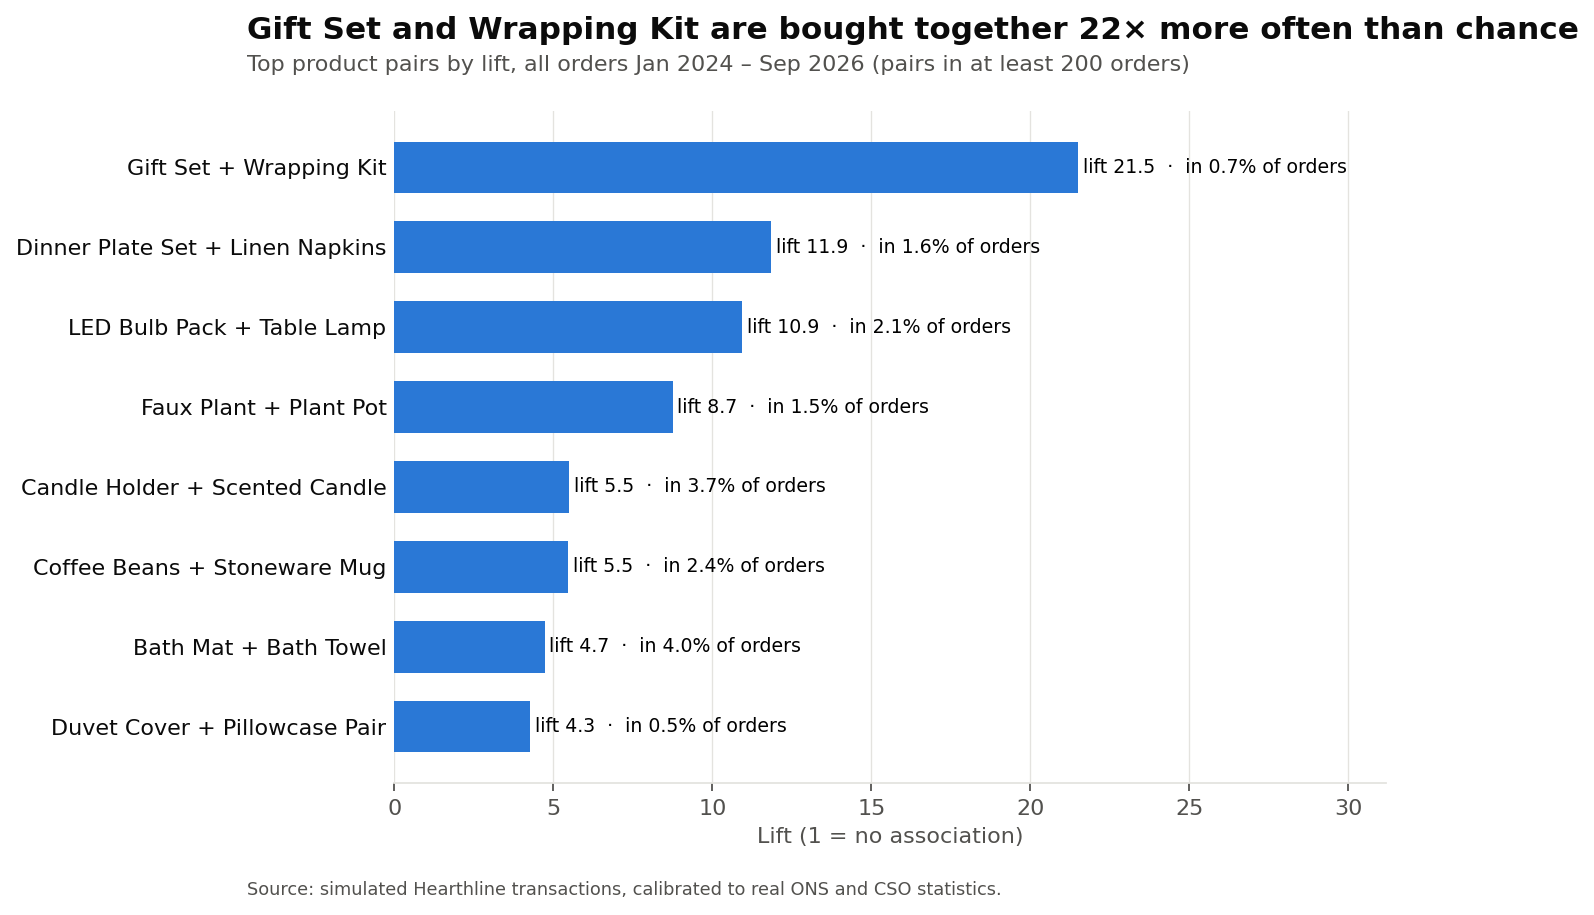

In [12]:
tp = top_pairs.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(tp["subcategory_x"] + " + " + tp["subcategory_y"], tp["lift"], color=BLUE, height=0.65)
for i, (l, s) in enumerate(zip(tp["lift"], tp["support_pct"])):
    ax.text(l + 0.15, i, f"lift {l:.1f}  ·  in {s:.1f}% of orders", va="center", fontsize=8.5)
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
ax.set_xlim(0, tp["lift"].max() * 1.45); ax.set_xlabel("Lift (1 = no association)")
top = top_pairs.iloc[0]
headline(fig, f"{top['subcategory_x']} and {top['subcategory_y']} are bought together {top['lift']:.0f}× more often than chance",
         "Top product pairs by lift, all orders Jan 2024 – Sep 2026 (pairs in at least 200 orders)")
plt.savefig("images/4_market_basket.png"); plt.show()

## 7. Where next? Online shopping in the UK, US and Taiwan (real data)

If Hearthline launched its website abroad, how mature is online retail there?

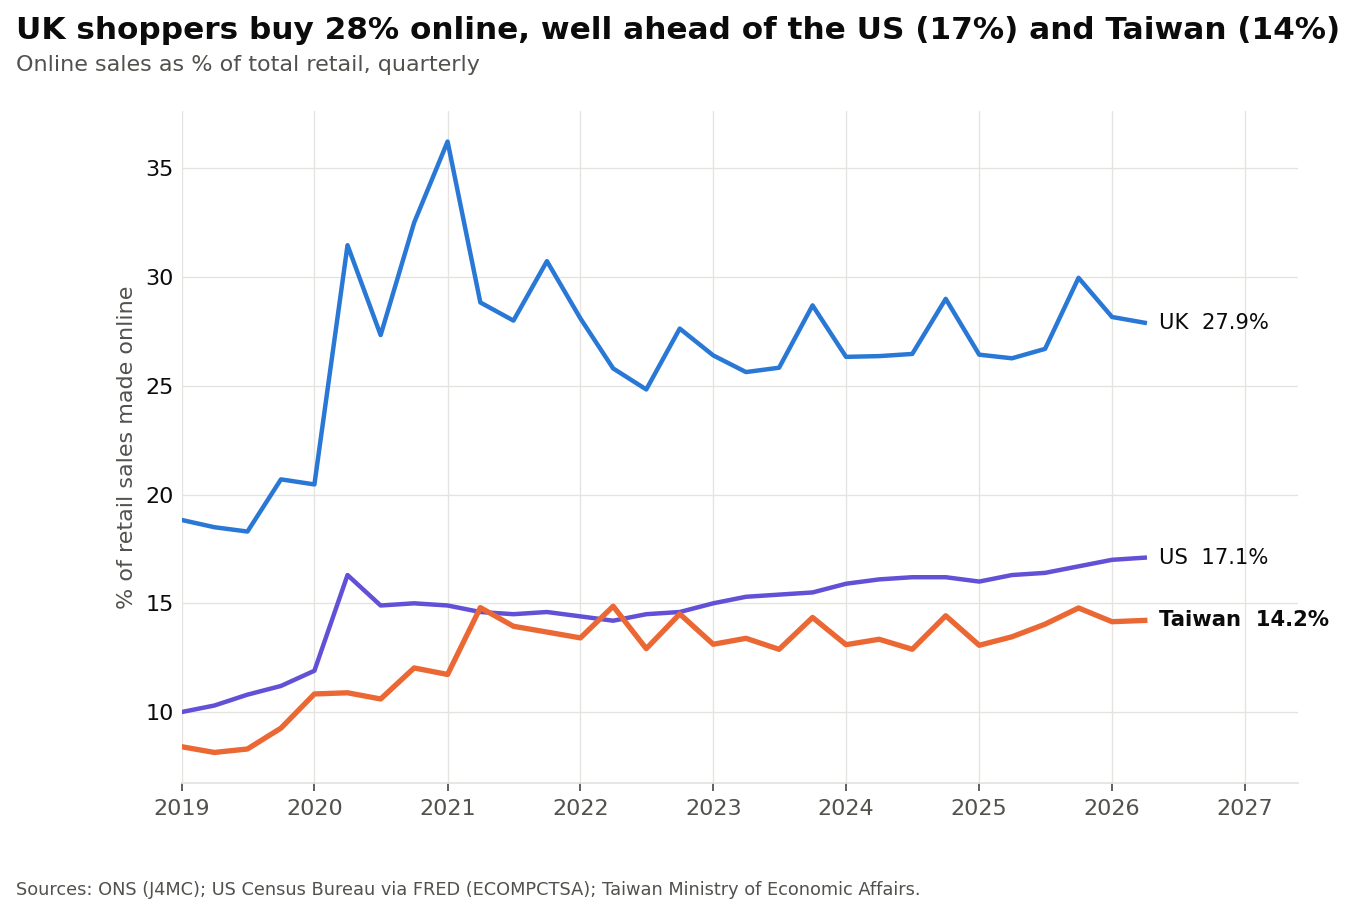

In [13]:
online = pd.read_csv("data/clean/online_share_by_market.csv", parse_dates=["date"])
online = online[online["date"] >= "2019-01-01"]
fig, ax = plt.subplots(figsize=(9, 5))
for mkt, color in [("UK", BLUE), ("US", VIOLET), ("Taiwan", ORANGE)]:
    d = online[online["market"] == mkt]
    if len(d):
        ax.plot(d["date"], d["online_share_pct"], color=color, linewidth=2.4 if mkt == "Taiwan" else 2, marker="o" if len(d) < 12 else None, markersize=4)
        last = d.iloc[-1]
        ax.text(last["date"] + pd.Timedelta(days=40), last["online_share_pct"], f"{mkt}  {last['online_share_pct']:.1f}%",
                va="center", fontsize=9.5, color=INK, fontweight="bold" if mkt == "Taiwan" else "normal")
ax.set_xlim(pd.Timestamp("2019-01-01"), online["date"].max() + pd.Timedelta(days=420))
ax.set_ylabel("% of retail sales made online"); ax.tick_params(axis="y", length=0)
latest = online.sort_values("date").groupby("market").last()["online_share_pct"]
headline(fig, f"UK shoppers buy {latest['UK']:.0f}% online, well ahead of the US ({latest['US']:.0f}%) and Taiwan ({latest['Taiwan']:.0f}%)",
         "Online sales as % of total retail, quarterly", source=REAL)
plt.savefig("images/5_online_share_markets.png"); plt.show()

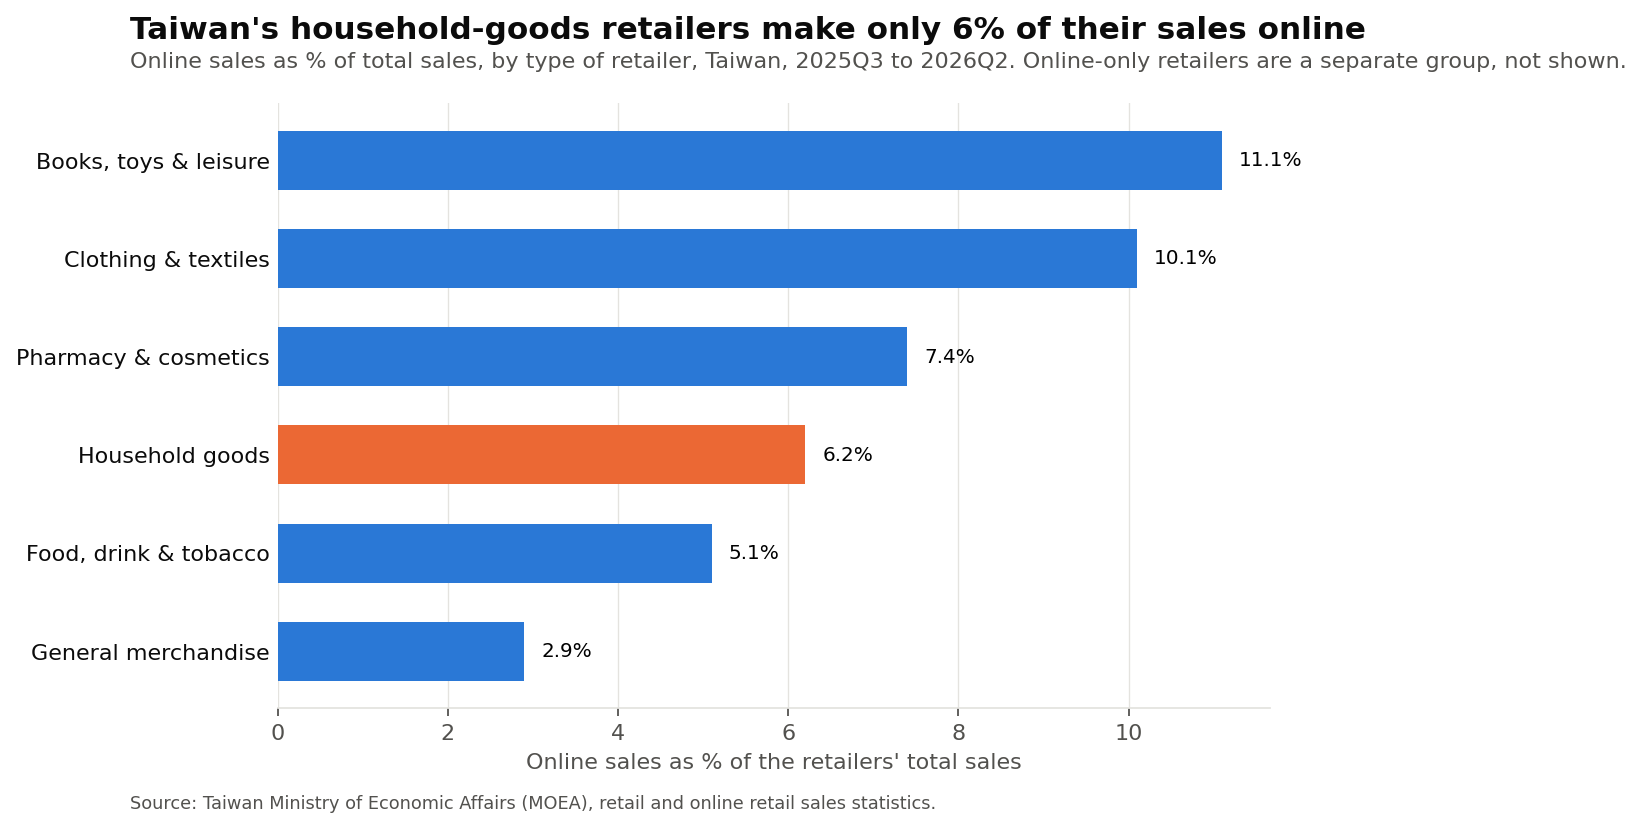

In [14]:
tw_cat = pd.read_csv("data/clean/taiwan_online_penetration_by_category.csv").sort_values("online_penetration_pct")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(tw_cat["category"], tw_cat["online_penetration_pct"], color=[ORANGE if c == "Household goods" else BLUE for c in tw_cat["category"]], height=0.6)
for i, v in enumerate(tw_cat["online_penetration_pct"]):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9)
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0); ax.set_xlabel("Online sales as % of the retailers' total sales")
hh = tw_cat.set_index("category").loc["Household goods", "online_penetration_pct"]
headline(fig, f"Taiwan's household-goods retailers make only {hh:.0f}% of their sales online",
         f"Online sales as % of total sales, by type of retailer, Taiwan, {tw_cat['period'].iloc[0]}. Online-only retailers are a separate group, not shown.",
         source="Source: Taiwan Ministry of Economic Affairs (MOEA), retail and online retail sales statistics.")
plt.savefig("images/6_taiwan_online_by_category.png"); plt.show()

### Market potential: size, growth and online share (real data)

Size is 2025 retail sales converted to pounds; growth is the compound annual growth rate 2019–2025 in local currency (nominal); online share is the latest quarter. See notebook 01, section 9.

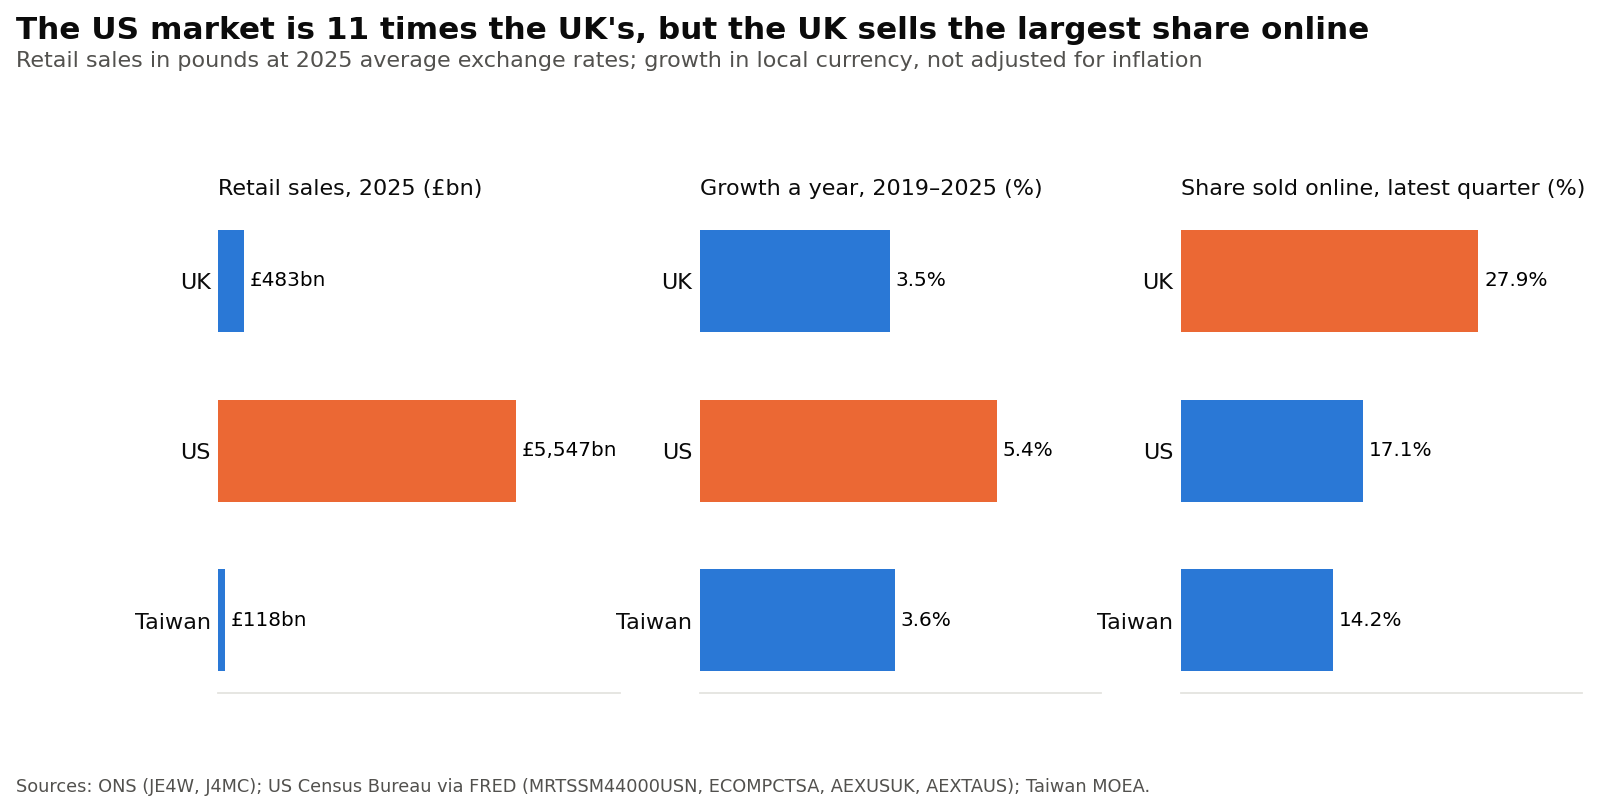

In [15]:
ms = pd.read_csv("data/clean/market_size_by_country.csv").set_index("market").loc[["UK", "US", "Taiwan"]]
panels = [("sales_2025_gbp_bn", "Retail sales, 2025 (£bn)", "£{:,.0f}bn"),
          ("cagr_local_pct", "Growth a year, 2019–2025 (%)", "{:.1f}%"),
          ("online_share_latest_pct", "Share sold online, latest quarter (%)", "{:.1f}%")]
fig, axes = plt.subplots(1, 3, figsize=(11, 4.4))
for ax, (col, label, fmt) in zip(axes, panels):
    vals = ms[col]
    hi = vals.idxmax()
    ax.barh(ms.index, vals, color=[ORANGE if m == hi else BLUE for m in ms.index], height=0.6)
    for i, v in enumerate(vals):
        ax.text(v + vals.max() * 0.02, i, fmt.format(v), va="center", fontsize=9)
    ax.set_xlim(0, vals.max() * 1.35); ax.invert_yaxis()
    ax.set_title(label, fontsize=10, loc="left", color=INK)
    ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0); ax.set_xticks([])
ratio = ms.loc["US", "sales_2025_gbp_bn"] / ms.loc["UK", "sales_2025_gbp_bn"]
headline(fig, f"The US market is {ratio:.0f} times the UK's, but the UK sells the largest share online",
         "Retail sales in pounds at 2025 average exchange rates; growth in local currency, not adjusted for inflation",
         top=0.8, source="Sources: ONS (JE4W, J4MC); US Census Bureau via FRED (MRTSSM44000USN, ECOMPCTSA, AEXUSUK, AEXTAUS); Taiwan MOEA.")
plt.savefig("images/7_market_potential.png"); plt.show()

## 8. Key numbers for the README (calculated, not typed)

In [16]:
import json
k = {
    "revenue_2025_ytd_m": round(kpi.loc[2025, "revenue"] / 1e6, 2),
    "revenue_2026_ytd_m": round(kpi.loc[2026, "revenue"] / 1e6, 2),
    "revenue_growth_2026_ytd_pct": round(kpi.loc[2026, "revenue_growth_pct"], 1),
    "aov_2026": round(kpi.loc[2026, "avg_order_value"], 2),
    "online_share_2026_pct": round(kpi.loc[2026, "online_share_pct"], 1),
    "gross_margin_2026_pct": round(kpi.loc[2026, "gross_margin_pct"], 1),
    "return_rate_online_pct": round(returns.loc[returns["channel"] == "Online", "refund"].sum() / sales.loc[sales["channel"] == "Online", "net_sales"].sum() * 100, 1),
    "return_rate_store_pct": round(returns.loc[returns["channel"] == "Store", "refund"].sum() / sales.loc[sales["channel"] == "Store", "net_sales"].sum() * 100, 1),
    "london_capture_index": round(cap.loc["London", "market_capture_index"], 2),
    "london_revenue_share_pct": round(cap.loc["London", "revenue_share"] * 100, 1),
    "london_spending_share_pct": round(cap.loc["London", "spending_share"] * 100, 1),
    "top_capture_city": cap["market_capture_index"].idxmax(),
    "top_capture_index": round(cap["market_capture_index"].max(), 2),
    "champions_customer_share_pct": round(seg.loc["Champions", "customer_share"] * 100, 1),
    "champions_revenue_share_pct": round(seg.loc["Champions", "revenue_share"] * 100, 1),
    "next_quarter_retention_pct": round(q1, 1),
    "top_pair": f"{top['subcategory_x']} + {top['subcategory_y']}",
    "top_pair_lift": round(top["lift"], 1),
    "online_share_latest": latest.round(1).to_dict(),
    "taiwan_household_goods_online_pct": round(hh, 1),
}
json.dump(k, open("data/clean/key_numbers.json", "w"), indent=2, default=str)
k

{'revenue_2025_ytd_m': np.float64(4.53), 'revenue_2026_ytd_m': np.float64(4.71), 'revenue_growth_2026_ytd_pct': np.float64(3.9), 'aov_2026': np.float64(50.48), 'online_share_2026_pct': np.float64(32.3), 'gross_margin_2026_pct': np.float64(51.4), 'return_rate_online_pct': np.float64(8.2), 'return_rate_store_pct': np.float64(2.8), 'london_capture_index': np.float64(0.49), 'london_revenue_share_pct': np.float64(20.9), 'london_spending_share_pct': np.float64(42.4), 'top_capture_city': 'Belfast', 'top_capture_index': np.float64(2.31), 'champions_customer_share_pct': np.float64(25.5), 'champions_revenue_share_pct': np.float64(57.8), 'next_quarter_retention_pct': np.float64(52.3), 'top_pair': 'Gift Set + Wrapping Kit', 'top_pair_lift': np.float64(21.5), 'online_share_latest': {'Taiwan': 14.2, 'UK': 27.9, 'US': 17.1}, 'taiwan_household_goods_online_pct': np.float64(6.2)}

## 9. Recommendations

*(The numbers are from the cells above; the reasoning is mine.)*

1. **Open a second London store before expanding abroad.** London holds most of the spending power among our 12 cities, but our single store captures well under its fair share. Belfast and Manchester show what a store can do in a city that draws shoppers in.
2. **Protect the Champions.** A small group of customers drives a large share of revenue. Early access and member-only offers cost less than winning new customers.
3. **Bundle the strong pairs** (e.g. duvet covers with pillowcases, lamps with bulbs) as ready-made sets online and at the till.
4. **Treat Taiwan as a later, online-first test.** Online retail there is growing but still smaller than in the UK, and household goods are among the least online categories. A marketplace pilot is cheaper than a full launch.

**Limitations:** the transactions are simulated (calibrated to real statistics, not real Hearthline sales); 2024 retail GVA for Glasgow, Bristol, Cardiff and Dublin is estimated; Dublin's income is for 2023 and converted from euro; US and Taiwan online-share definitions differ slightly from the ONS one.